[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/12_good_practices_mini_project.ipynb)

# 12 · Good Practices, Pitfalls, and a Mini Project: Is My Simulation Converged?

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~75 min*

Running MD is easy; getting numbers you can defend is not. This final notebook is about **reliability**:
equilibration, correlated samples, honest error bars with block averaging, why independent **replicas** matter,
the classic pitfalls and how to recognize them, and what to put in a methods section. Then we turn the course's
protocol into a stand-alone script with a Slurm job file so you can run real simulations on a GPU cluster, and
finish with a mini project.

**Learning objectives.** By the end of this notebook you will be able to:

- detect the equilibration period and discard it
- compute autocorrelation times and the number of effectively independent samples
- estimate error bars correctly with block averaging and with independent replicas
- recognize common MD pitfalls, write a complete methods paragraph, and scale the workflow to HPC

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm', 'pdbfixer', 'mdtraj'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. Data: three independent chignolin runs

We use the precomputed 3 × 0.2 ns production runs from Notebooks 08–09 (thermodynamic log every 2 ps and peptide
coordinates every 2 ps). As our observable we take the backbone RMSD from the crystal structure, a typical
quantity people report, and the potential energy.

In [2]:
import json, os, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md

TOP = f"{DATA_DIR}/trajectories/chignolin_protein.pdb"
ref = md.load(TOP)
bb = ref.topology.select("backbone")
rmsd = {}
for i in range(3):
    tr = md.load(f"{DATA_DIR}/trajectories/chignolin_rep{i}.dcd", top=TOP)
    rmsd[i] = md.rmsd(tr, ref, atom_indices=bb) * 10            # Å
thermo = pd.read_csv(f"{DATA_DIR}/trajectories/chignolin_thermo.csv")
t = np.arange(1, len(rmsd[0]) + 1) * 2.0
print({f"replica {i}": f"{len(v)} frames, mean RMSD {v.mean():.2f} Å" for i, v in rmsd.items()})

{'replica 0': '100 frames, mean RMSD 0.55 Å', 'replica 1': '100 frames, mean RMSD 0.49 Å', 'replica 2': '100 frames, mean RMSD 0.50 Å'}


## 2. Pitfall 1: averaging over a system that is still relaxing

Even after restrained equilibration, the structure relaxes for a while once restraints are released. A **running
average** that drifts tells you to discard more of the start. Here we look at the cumulative mean of the RMSD
and the potential energy.

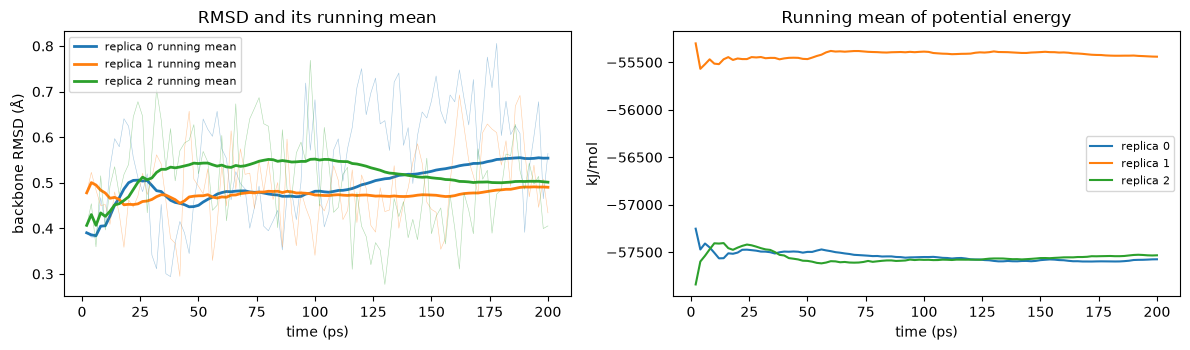

discarding the first 20 ps of each replica -> 90 frames per replica kept


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i in range(3):
    r = rmsd[i]
    ax[0].plot(t, r, lw=0.4, alpha=0.4, color=f"C{i}")
    ax[0].plot(t, np.cumsum(r) / np.arange(1, len(r) + 1), lw=2, color=f"C{i}", label=f"replica {i} running mean")
    e = thermo[thermo.replica == i].potential_kJmol.values
    ax[1].plot(t, np.cumsum(e) / np.arange(1, len(e) + 1), color=f"C{i}", label=f"replica {i}")
ax[0].set(xlabel="time (ps)", ylabel="backbone RMSD (Å)", title="RMSD and its running mean"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="time (ps)", ylabel="kJ/mol", title="Running mean of potential energy"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

DISCARD_PS = 20
keep = t > DISCARD_PS
print(f"discarding the first {DISCARD_PS} ps of each replica -> {keep.sum()} frames per replica kept")

## 3. Pitfall 2: treating correlated frames as independent

Consecutive frames 2 ps apart are almost identical, so 90 frames are **not** 90 independent measurements. The
**autocorrelation function** $C(\tau)$ shows how quickly the memory decays; integrating it gives the
**statistical inefficiency** $g = 1 + 2\sum_\tau C(\tau)$: roughly, one in every $g$ frames is independent.

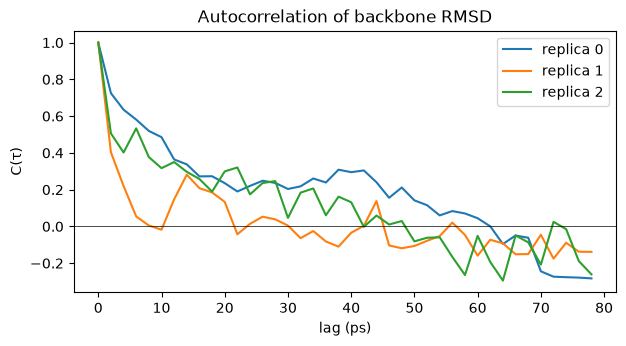

,mean RMSD (Å),g (frames),correlation time (ps),N frames,N effective,naive SEM,corrected SEM
replica,,,,,,,
0,0.560,15.501,15.501,90,5.806000,0.013,0.051
1,0.494,2.342,2.342,90,38.432999,0.009,0.013
2,0.505,10.638,10.638,90,8.460000,0.011,0.035


In [4]:
def autocorr(x, max_lag):
    x = np.asarray(x) - np.mean(x)
    var = np.dot(x, x) / len(x)
    return np.array([np.dot(x[:len(x) - k], x[k:]) / (len(x) - k) / var for k in range(max_lag)])

def statistical_inefficiency(x):
    c = autocorr(x, len(x) // 2)
    g = 1.0
    for k in range(1, len(c)):
        if c[k] <= 0:                # stop at the first zero crossing
            break
        g += 2 * c[k] * (1 - k / len(x))
    return g

plt.figure(figsize=(7, 3.4))
rows = []
for i in range(3):
    x = rmsd[i][keep]
    c = autocorr(x, 40)
    plt.plot(np.arange(40) * 2.0, c, label=f"replica {i}")
    g = statistical_inefficiency(x)
    rows.append({"replica": i, "mean RMSD (Å)": x.mean(), "g (frames)": g, "correlation time (ps)": g * 2.0 / 2,
                 "N frames": len(x), "N effective": len(x) / g,
                 "naive SEM": x.std(ddof=1) / np.sqrt(len(x)), "corrected SEM": x.std(ddof=1) / np.sqrt(len(x) / g)})
plt.axhline(0, color="k", lw=0.5); plt.xlabel("lag (ps)"); plt.ylabel("C(τ)"); plt.title("Autocorrelation of backbone RMSD")
plt.legend(); plt.show()
stats = pd.DataFrame(rows).set_index("replica")
stats.round(3)

The naive standard error ($\sigma/\sqrt{N}$) is too small by a factor of about $\sqrt{g}$. Reporting it makes results
look far more precise than they are.

## 4. Block averaging

Block averaging (Flyvbjerg & Petersen, *J. Chem. Phys.* 1989) is a robust alternative that needs no
autocorrelation fit: split the data into $M$ blocks, average each block, and compute the standard error of the
block means. When blocks are longer than the correlation time, the estimate reaches a **plateau**, which is the
honest error bar.

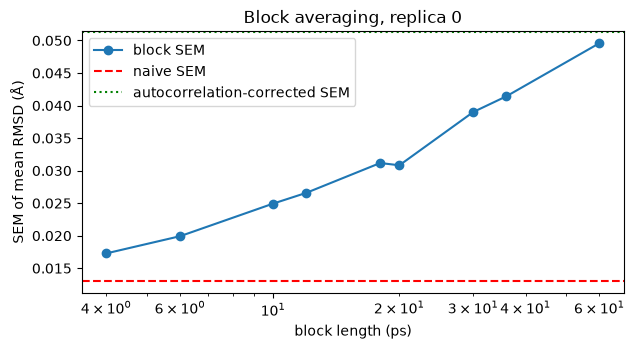

,0,1,2,3,4,5,6,7,8
block length (ps),4.0000,6.0000,10.0000,12.0000,18.0000,20.0000,30.000,36.0000,60.0000
SEM (Å),0.0173,0.0199,0.0249,0.0266,0.0312,0.0308,0.039,0.0414,0.0496


In [5]:
def block_sem(x, n_blocks):
    n = len(x) // n_blocks
    means = np.asarray(x[: n * n_blocks]).reshape(n_blocks, n).mean(1)
    return means.std(ddof=1) / np.sqrt(n_blocks), n

x = rmsd[0][keep]
block_counts = [45, 30, 18, 15, 10, 9, 6, 5, 3]
res = [(n_frames_per_block * 2.0, sem) for sem, n_frames_per_block in (block_sem(x, m) for m in block_counts)]
bl = pd.DataFrame(res, columns=["block length (ps)", "SEM (Å)"])
plt.figure(figsize=(7, 3.4))
plt.plot(bl["block length (ps)"], bl["SEM (Å)"], "o-", label="block SEM")
plt.axhline(stats.loc[0, "naive SEM"], color="r", ls="--", label="naive SEM")
plt.axhline(stats.loc[0, "corrected SEM"], color="g", ls=":", label="autocorrelation-corrected SEM")
plt.xscale("log"); plt.xlabel("block length (ps)"); plt.ylabel("SEM of mean RMSD (Å)"); plt.legend(); plt.title("Block averaging, replica 0")
plt.show()
bl.round(4).T

The block SEM grows with block length and levels off (noisily, because few long blocks fit into 180 ps). If it
never levels off, the run is **too short** to estimate the error at all, which is itself an important result.

## 5. Replicas: the most honest error bar

Independent replicas (different random velocities) are statistically independent by construction, and they also
reveal when runs get stuck in different regions, something no single-trajectory analysis can detect.

In [6]:
means = stats["mean RMSD (Å)"]
print("per-replica means (Å):", {k: round(float(v), 3) for k, v in means.items()})
print(f"across replicas: {means.mean():.3f} ± {means.std(ddof=1) / np.sqrt(len(means)):.3f} Å (mean ± SEM, n = 3)")
print(f"largest within-replica corrected SEM: {stats['corrected SEM'].max():.3f} Å")

per-replica means (Å): {0: 0.56, 1: 0.494, 2: 0.505}
across replicas: 0.520 ± 0.020 Å (mean ± SEM, n = 3)
largest within-replica corrected SEM: 0.051 Å


If the spread between replica means is much larger than the within-replica error bars, each run is sampling a
different part of the landscape and none of them is converged: run longer, run more replicas, or use enhanced
sampling. Three replicas is the minimum people expect in a paper; five to ten is better.

## 6. Classic pitfalls and how to spot them

| Symptom | Likely cause | Fix |
|---|---|---|
| Energy explodes, NaN coordinates, "particle coordinate is NaN" | no minimization, clashes, timestep too large, missing constraints/HMR | minimize, equilibrate with restraints, use 2 fs (or 4 fs + HMR) |
| Protein "jumps" or looks broken in VMD/PyMOL | periodic wrapping, not a real event | make molecules whole / centre before analysis (`traj.image_molecules()`) |
| RMSD keeps rising | still equilibrating, unfolding, or wrong protonation/missing residues | check preparation, discard start, run longer |
| Ligand leaves the pocket in ns | wrong pose, protonation, or parameters, or a genuinely weak binder | check the pose, charges, protonation; run replicas |
| Water density far from 1 g/cm³ | barostat off or wrong water model | NPT equilibration; match water model to force field |
| Protein interacts with its image | box too small | larger padding; check minimum image distance on the trajectory |
| Temperature "perfectly" constant | wrong thermostat (velocity rescaling/Berendsen) | Langevin, Nosé–Hoover, v-rescale |
| Results differ between replicas | insufficient sampling | longer runs, more replicas, enhanced sampling |

## 7. Methods checklist (what reviewers look for)

Starting structure (PDB ID, chain, missing residues and how they were handled), protonation method and pH, force
field and version, water model, ions and concentration, box shape and padding, nonbonded treatment (PME,
cutoff), constraints and HMR, timestep, integrator and thermostat (friction), barostat, minimization and
equilibration protocol with restraints, production length, number of replicas and seeds, software versions,
analysis methods and how error bars were computed. Here is a paragraph generated from the provenance records of
this course's data:

In [7]:
prov = json.load(open(f"{DATA_DIR}/provenance.json"))
c = prov["chignolin"]
methods = (
    f"Simulations of {c['system']} were performed with OpenMM {c['openmm']}. The {c['force_field']} force field was used, "
    f"with {c['solvent']} ({c['atoms']} atoms in total). Long-range electrostatics used {c['nonbonded']}. "
    f"Protocol: {c['protocol']}. Dynamics used the {c['integrator']}; pressure was controlled with a {c['barostat']}. "
    f"{c['replicas']} independent replicas of {c['ns_per_replica']} ns were run with different random seeds; "
    f"frames were saved every {c['save_interval_ps']} ps. The first {DISCARD_PS} ps of each replica were discarded, and "
    f"uncertainties are reported as the standard error over replicas."
)
print(methods)

Simulations of CLN025 chignolin variant YYDPETGTWY, PDB 5AWL chain A, prepared with PDBFixer, H added at pH 7 were performed with OpenMM 8.6.1. The amber14-all.xml (ff14SB) + amber14/tip3pfb.xml force field was used, with TIP3P-FB water, 1.0 nm padding, cubic box, 0.15 M NaCl (3258-3387 atoms in total). Long-range electrostatics used PME, 1.0 nm cutoff. Protocol: minimize; 20 ps NVT + 20 ps NPT with 400 kJ/mol/nm2 heavy-atom restraints; production NPT. Dynamics used the LangevinMiddleIntegrator 300 K, 1/ps, 4 fs, HBonds constraints, hydrogen mass 1.5 amu (HMR); pressure was controlled with a MonteCarloBarostat 1 bar, every 25 steps. 3 independent replicas of 0.2 ns were run with different random seeds; frames were saved every 2.0 ps. The first 20 ps of each replica were discarded, and uncertainties are reported as the standard error over replicas.


## 8. Scaling up: a stand-alone script and a Slurm job

Notebooks are great for learning; real simulations run as scripts on GPU nodes. The cell below writes a complete,
command-line OpenMM script that implements this course's protocol (prepare → solvate → minimize → NVT → NPT →
production with checkpoints, resuming automatically if a checkpoint exists), plus a Slurm submission file.
We then run the script for a few picoseconds on the CPU to prove that it works, and run it a second time with a longer
`--ns` to show that it resumes from its checkpoint.

In [8]:
os.makedirs("output/hpc", exist_ok=True)
script = r"""#!/usr/bin/env python
# Course protocol as a script:  python run_md.py input.pdb --ns 100 --platform CUDA
import argparse, os, sys
import openmm
from openmm import app, unit
from pdbfixer import PDBFixer

p = argparse.ArgumentParser()
p.add_argument("pdb"); p.add_argument("--ns", type=float, default=10.0)
p.add_argument("--platform", default="CUDA"); p.add_argument("--out", default="md")
p.add_argument("--seed", type=int, default=1); p.add_argument("--eq-ps", type=float, default=100.0)
a = p.parse_args()
os.makedirs(a.out, exist_ok=True)
DT = 0.004 * unit.picoseconds
ff = app.ForceField("amber14-all.xml", "amber14/tip3pfb.xml")
chk = os.path.join(a.out, "prod.chk")

start_pdb = os.path.join(a.out, "system.pdb")
if os.path.exists(chk) and os.path.exists(start_pdb):
    # Resuming: reuse the exact solvated system the checkpoint belongs to (solvation is not reproducible atom by atom)
    m = app.PDBFile(start_pdb)
else:
    fixer = PDBFixer(filename=a.pdb)
    fixer.removeHeterogens(keepWater=False); fixer.findMissingResidues(); fixer.missingResidues = {}
    fixer.findNonstandardResidues(); fixer.replaceNonstandardResidues(); fixer.findMissingAtoms(); fixer.addMissingAtoms()
    m = app.Modeller(fixer.topology, fixer.positions); m.addHydrogens(ff, pH=7.0)
    m.addSolvent(ff, padding=1.0 * unit.nanometer, ionicStrength=0.15 * unit.molar, boxShape="dodecahedron")
    app.PDBFile.writeFile(m.topology, m.positions, open(start_pdb, "w"))
solute = [at.index for at in m.topology.atoms() if at.residue.name not in ("HOH", "NA", "CL")]
heavy = [i for i in solute if list(m.topology.atoms())[i].element.symbol != "H"]
system = ff.createSystem(m.topology, nonbondedMethod=app.PME, nonbondedCutoff=1.0 * unit.nanometer,
                         constraints=app.HBonds, hydrogenMass=1.5 * unit.amu)
rest = openmm.CustomExternalForce("0.5*k_restr*periodicdistance(x,y,z,x0,y0,z0)^2")
rest.addGlobalParameter("k_restr", 1000.0)
for q in ("x0", "y0", "z0"): rest.addPerParticleParameter(q)
for i in heavy: rest.addParticle(i, m.positions[i].value_in_unit(unit.nanometer))
system.addForce(rest)
baro = openmm.MonteCarloBarostat(1 * unit.bar, 300 * unit.kelvin, 25); system.addForce(baro)
integ = openmm.LangevinMiddleIntegrator(300 * unit.kelvin, 1 / unit.picosecond, DT); integ.setRandomNumberSeed(a.seed)
sim = app.Simulation(m.topology, system, integ, openmm.Platform.getPlatformByName(a.platform))

n_prod = int(a.ns * 1000 / 0.004)
if os.path.exists(chk):
    sim.loadCheckpoint(chk); print("resumed at step", sim.currentStep, flush=True)
else:
    sim.context.setPositions(m.positions); sim.minimizeEnergy()
    sim.context.setVelocitiesToTemperature(300 * unit.kelvin, a.seed)
    baro.setFrequency(0); sim.context.reinitialize(preserveState=True)
    sim.step(int(a.eq_ps / 2 / 0.004))                       # NVT, restrained
    baro.setFrequency(25); sim.context.reinitialize(preserveState=True)
    sim.step(int(a.eq_ps / 2 / 0.004))                       # NPT, restrained
    sim.context.setParameter("k_restr", 0.0); sim.currentStep = 0
every = max(1, int(10 / 0.004))                              # save every 10 ps
sim.reporters += [app.XTCReporter(os.path.join(a.out, "prod.xtc"), every, append=os.path.exists(chk), atomSubset=solute),
                  app.StateDataReporter(os.path.join(a.out, "prod.log"), every, step=True, time=True, temperature=True,
                                        density=True, speed=True, append=os.path.exists(chk)),
                  app.CheckpointReporter(chk, every * 10)]
sim.step(max(0, n_prod - sim.currentStep))
sim.saveCheckpoint(chk); print("done at step", sim.currentStep, flush=True)
"""
open("output/hpc/run_md.py", "w").write(script)

slurm = """#!/bin/bash
#SBATCH --job-name=md-chignolin
#SBATCH --partition=gpu            # your cluster's GPU partition
#SBATCH --gres=gpu:1
#SBATCH --cpus-per-task=4
#SBATCH --mem=8G
#SBATCH --time=24:00:00
#SBATCH --array=1-3                # three independent replicas
module load cuda                   # site-specific; or rely on the conda environment
source activate practical-molecular-dynamics-course
python run_md.py 5AWL.pdb --ns 500 --platform CUDA --seed ${SLURM_ARRAY_TASK_ID} --out rep${SLURM_ARRAY_TASK_ID}
# If the job hits the time limit, resubmit the same command: it resumes from rep*/prod.chk.
"""
open("output/hpc/submit.slurm", "w").write(slurm)
print("wrote output/hpc/run_md.py and output/hpc/submit.slurm")

wrote output/hpc/run_md.py and output/hpc/submit.slurm


In [9]:
# Smoke test on the CPU with the cached chignolin structure: 4 ps equilibration + 20 ps production,
# then "resubmit" asking for 40 ps in total, which resumes from the checkpoint instead of starting over.
import shutil
shutil.rmtree("output/hpc/test", ignore_errors=True)
for ns in ("0.02", "0.04"):
    t0 = time.time()
    r = subprocess.run([sys.executable, "output/hpc/run_md.py", f"{DATA_DIR}/structures/5AWL.pdb", "--ns", ns,
                        "--eq-ps", "4", "--platform", "CPU", "--out", "output/hpc/test"], capture_output=True, text=True)
    print(f"--ns {ns}: exit code {r.returncode} in {time.time() - t0:.0f} s |", r.stdout.strip().replace(chr(10), " | "),
          r.stderr[-1500:])
print(open("output/hpc/test/prod.log").read())

--ns 0.02: exit code 0 in 71 s | done at step 5000 


--ns 0.04: exit code 0 in 27 s | resumed at step 5000 | done at step 10000 
#"Step","Time (ps)","Temperature (K)","Density (g/mL)","Speed (ns/day)"
2500,13.999999999998902,302.5768036401179,1.0383354474394686,0
5000,24.000000000001354,308.73455545799595,1.048951921980959,50.8
7500,34.00000000000291,298.55437610921575,1.0344205413312773,0
10000,43.99999999999737,294.61147473131905,1.049183602010646,66.2



**The same workflow in other engines.** The concepts map one-to-one; only the commands change.

| Step | OpenMM (this course) | GROMACS | AMBER |
|---|---|---|---|
| Topology + force field | `ForceField("amber14-all.xml", ...)` | `gmx pdb2gmx -ff amber14sb -water tip3p` | `tleap` with `leaprc.protein.ff14SB` |
| Box + water + ions | `Modeller.addSolvent(...)` | `gmx editconf -bt dodecahedron -d 1.0`, `gmx solvate`, `gmx genion` | `solvateOct`, `addIonsRand` in tleap |
| Minimize / NVT / NPT / MD | `minimizeEnergy`, `step` | `gmx grompp` + `gmx mdrun` with `.mdp` files | `pmemd.cuda -i min.in / nvt.in / npt.in / md.in` |
| Ligand parameters | openmmforcefields (GAFF2, OpenFF) | ACPYPE (GAFF2) or CGenFF | antechamber + parmchk2 (GAFF2) |
| Restart | `loadCheckpoint` | `gmx mdrun -cpi state.cpt` | `-x` restart file `.rst7` |

On a typical cluster, put the conda environment in your home or project space, test for 10 minutes on an
interactive GPU node, then submit replicas as a job array like the one above.

## 9. Mini project: is the CLN025 hairpin stable in these simulations?

**Your task.** Using the three replicas, report the fraction of time the hairpin stays "native" (backbone RMSD
below 1.5 Å from the crystal structure, after discarding the first 20 ps), with an error bar from the replicas
and a block-averaged error bar for each replica. Then write two sentences of interpretation, including what you
could and could not conclude from 3 × 0.2 ns about the folding stability of chignolin (which folds and unfolds on
microsecond time scales at 300 K).

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
fractions, block_errs = [], []
for i in range(3):
    native = (rmsd[i][keep] < 1.5).astype(float)
    fractions.append(native.mean())
    block_errs.append(block_sem(native, 5)[0])            # 5 blocks of 36 ps
fractions = np.array(fractions)
for i in range(3):
    print(f"replica {i}: native fraction {fractions[i]:.3f} ± {block_errs[i]:.3f} (block SEM)")
print(f"all replicas: {fractions.mean():.3f} ± {fractions.std(ddof=1) / np.sqrt(3):.3f} (SEM over replicas)")
# Interpretation: on the nanosecond time scale the crystal hairpin is (or is not) stable in all replicas, which
# supports the force field keeping the folded state stable. It says nothing about the folded population at
# equilibrium: folding/unfolding takes microseconds, so 3 x 0.2 ns cannot sample transitions between the states.
```

</details>

## Key takeaways

- Discard the start, then measure correlation: N frames ≠ N independent samples.
- Block averaging and independent replicas give honest error bars; naive SEMs are too small.
- Know the classic pitfalls (wrapping artifacts, small boxes, wrong thermostats, unconverged sampling).
- Report every protocol detail, and scale up with scripts, checkpoints, and job arrays on GPUs.

**Next:** You have finished the course. Revisit [Notebook 11](11_protein_ligand_md.ipynb) with your own target, or explore the [related repositories](https://github.com/hentablihamza).